# Ex08


Tự viết toàn bộ code. File này không có lời giải.

Làm lần lượt sáu phần:

1. Mã hóa (LabelEncoder và OneHotEncoder)
2. Ghép thành một bảng số duy nhất (concat)
3. Chuẩn hóa (StandardScaler hoặc MinMaxScaler)
4. Đưa bảng đã chuẩn hóa vào KMeans để gom cụm
5. Elbow để xem k
6. KNN để dự đoán Response

Dữ liệu: data/marketing_campaign.csv, dấu phân tách là tab.

Dùng đúng các cột sau, không thêm cột khác vào bảng đưa vào mô hình:

| Cột | Việc phải làm |
|---|---|
| Education | LabelEncoder |
| Marital_Status | OneHotEncoder |
| Income, Recency, MntWines, MntMeatProducts | giữ nguyên, vì đã là số |

Bỏ các dòng thiếu Income trước khi mã hóa. Không đưa Response vào bảng đặc trưng. Response chỉ dùng làm nhãn ở phần KNN.

random_state=0. Với KMeans đặt thêm n_init=10.


## 1. Mã hóa

Education và Marital_Status là chữ. KMeans không nhận chữ.

In classes_ của LabelEncoder sau khi fit. In tên cột do OneHotEncoder sinh ra.


In [436]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt


In [437]:
df = pd.read_csv('marketing_campaign.csv', sep = '\t')
df.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,...,7,0,0,0,0,0,0,3,11,1
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,...,5,0,0,0,0,0,0,3,11,0
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,...,4,0,0,0,0,0,0,3,11,0
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,...,6,0,0,0,0,0,0,3,11,0
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,...,5,0,0,0,0,0,0,3,11,0


In [438]:
df.shape

(2240, 29)

In [439]:
df.columns

Index(['ID', 'Year_Birth', 'Education', 'Marital_Status', 'Income', 'Kidhome',
       'Teenhome', 'Dt_Customer', 'Recency', 'MntWines', 'MntFruits',
       'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts',
       'MntGoldProds', 'NumDealsPurchases', 'NumWebPurchases',
       'NumCatalogPurchases', 'NumStorePurchases', 'NumWebVisitsMonth',
       'AcceptedCmp3', 'AcceptedCmp4', 'AcceptedCmp5', 'AcceptedCmp1',
       'AcceptedCmp2', 'Complain', 'Z_CostContact', 'Z_Revenue', 'Response'],
      dtype='object')

In [440]:
columns = ['Education', 'Marital_Status', 'Income', 'Recency', 'MntWines', 'MntMeatProducts']

df1 = df[columns]
df1.head()

,Education,Marital_Status,Income,Recency,MntWines,MntMeatProducts
0,Graduation,Single,58138.0,58,635,546
1,Graduation,Single,46344.0,38,11,6
2,Graduation,Together,71613.0,26,426,127
3,Graduation,Together,26646.0,26,11,20
4,PhD,Married,58293.0,94,173,118


In [441]:
from sklearn.preprocessing import OneHotEncoder, LabelEncoder

le = LabelEncoder()

df1['Education'] = le.fit_transform(df1['Education'])
print('Classes:', le.classes_)

Classes: ['2n Cycle' 'Basic' 'Graduation' 'Master' 'PhD']


C:\Users\lenovo\AppData\Local\Temp\ipykernel_24464\1574592992.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df1['Education'] = le.fit_transform(df1['Education'])


In [442]:
ohe = OneHotEncoder(sparse_output=False)

marital_encoded = ohe.fit_transform(df1[['Marital_Status']])
marital_encoded

array([[0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 1., 0., 0.],
       ...,
       [0., 0., 1., ..., 0., 0., 0.],
       [0., 0., 0., ..., 1., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.]])

In [443]:
#In tên cột
ohe = OneHotEncoder(sparse_output=False)

marital_encoded = ohe.fit_transform(df1[['Marital_Status']])
print('Tên cột:', ohe.get_feature_names_out(['Marital_Status']))

Tên cột: ['Marital_Status_Absurd' 'Marital_Status_Alone' 'Marital_Status_Divorced'
 'Marital_Status_Married' 'Marital_Status_Single'
 'Marital_Status_Together' 'Marital_Status_Widow' 'Marital_Status_YOLO']


In [444]:
#Tao DataFrame cho cac cot OHE
df_marital = pd.DataFrame(
    marital_encoded,
    columns=ohe.get_feature_names_out(['Marital_Status']),
    index = df1.index
)

In [445]:
df1.isna().sum()

Education           0
Marital_Status      0
Income             24
Recency             0
MntWines            0
MntMeatProducts     0
dtype: int64

In [446]:
df1 = df1.dropna(subset=['Income'])

df1.isna().sum()

Education          0
Marital_Status     0
Income             0
Recency            0
MntWines           0
MntMeatProducts    0
dtype: int64

In [447]:
df_encoded = df.copy()
X = df_encoded.drop(columns=['Response'])

y = df_encoded['Response']  

In [448]:
from sklearn.cluster import KMeans

kmeans = KMeans(
    n_clusters=3,
    random_state=0,
    n_init=10
)

In [449]:
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier

X_train, X_test, y_train, y_test = train_test_split(
    X,y,
    test_size=0.2,
    random_state=0
)

knn = KNeighborsClassifier(n_neighbors=5)

**Trả lời, không cần code.**

1. LabelEncoder xếp Education theo thứ tự nào? Thứ tự đó có phải Basic, rồi 2n Cycle, Graduation, Master, PhD hay không?
- LabelEncoder mặc định sắp xếp các giá trị dạng chuỗi theo thứ tự từ điển (alphabet). Không, thứ tự là '2n Cycle' 'Basic' 'Graduation' 'Master' 'PhD'

2. Vì sao Marital_Status dùng OneHotEncoder còn Education lại dùng LabelEncoder trong bài này?
- Marital_Status dùng OHE vì trong bài này OHE phù hợp với biến không có thứ tự.
- Education dùng LabelEncoder vì trong bài này LE  chuyển Education thành số nhưng không tự bảo toàn thứ bậc học vấn thực tế.


## 2. Ghép thành một bảng số duy nhất

Ghép ba khối theo cột: số của Education, các cột biến giả của Marital_Status, và bốn cột số. Kết quả là một DataFrame, mọi cột đều là số, số dòng bằng số dòng sau khi bỏ Income thiếu.

In shape và columns.


In [452]:
df1 = df[columns].dropna(subset=['Income']).copy()

le = LabelEncoder()
df1['Education'] = le.fit_transform(df1['Education'])

ohe = OneHotEncoder(sparse_output=False)
marital_encoded = ohe.fit_transform(df1[['Marital_Status']])

df_marital = pd.DataFrame(
    marital_encoded,
    columns=ohe.get_feature_names_out(['Marital_Status']),
    index=df1.index
)
df2 = pd.concat([
    df1['Education'],
    df_marital,
    df1[['Income','Recency', 'MntWines', 'MntMeatProducts']]
], axis=1)


In [453]:
df2.shape

(2216, 13)

In [454]:
df2.columns

Index(['Education', 'Marital_Status_Absurd', 'Marital_Status_Alone',
       'Marital_Status_Divorced', 'Marital_Status_Married',
       'Marital_Status_Single', 'Marital_Status_Together',
       'Marital_Status_Widow', 'Marital_Status_YOLO', 'Income', 'Recency',
       'MntWines', 'MntMeatProducts'],
      dtype='object')

**Trả lời.**

3. Bảng ghép có bao nhiêu dòng, bao nhiêu cột? Kể tên các cột biến giả.
- Có 2216 dòng, 13 cột.
- 'Marital_Status_Absurd', 'Marital_Status_Alone',
       'Marital_Status_Divorced', 'Marital_Status_Married',
       'Marital_Status_Single', 'Marital_Status_Together',
       'Marital_Status_Widow', 'Marital_Status_YOLO'


## 3. Chuẩn hóa

Chọn một trong hai: StandardScaler hoặc MinMaxScaler. Fit trên toàn bộ bảng vừa ghép. In trung bình mỗi cột sau khi scale, làm tròn 3 chữ số.


In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

df_scaled = pd.DataFrame(
    scaler.fit_transform(df2),
    columns=df2.columns,
    index=df2.index
)

df_scaled.head()

,Education,Marital_Status_Absurd,Marital_Status_Alone,Marital_Status_Divorced,Marital_Status_Married,Marital_Status_Single,Marital_Status_Together,Marital_Status_Widow,Marital_Status_YOLO,Income,Recency,MntWines,MntMeatProducts
0,-0.350527,-0.030056,-0.036819,-0.341958,-0.794110,1.924807,-0.590553,-0.188452,-0.030056,0.234063,0.310532,0.978226,1.690227
1,-0.350527,-0.030056,-0.036819,-0.341958,-0.794110,1.924807,-0.590553,-0.188452,-0.030056,-0.234559,-0.380509,-0.872024,-0.717986
2,-0.350527,-0.030056,-0.036819,-0.341958,-0.794110,-0.519533,1.693329,-0.188452,-0.030056,0.769478,-0.795134,0.358511,-0.178368
3,-0.350527,-0.030056,-0.036819,-0.341958,-0.794110,-0.519533,1.693329,-0.188452,-0.030056,-1.017239,-0.795134,-0.872024,-0.655551
4,1.429011,-0.030056,-0.036819,-0.341958,1.259271,-0.519533,-0.590553,-0.188452,-0.030056,0.240221,1.554407,-0.391671,-0.218505


In [456]:
print(df_scaled.mean().round(3))

Education                  0.0
Marital_Status_Absurd     -0.0
Marital_Status_Alone       0.0
Marital_Status_Divorced   -0.0
Marital_Status_Married    -0.0
Marital_Status_Single     -0.0
Marital_Status_Together   -0.0
Marital_Status_Widow       0.0
Marital_Status_YOLO        0.0
Income                     0.0
Recency                   -0.0
MntWines                  -0.0
MntMeatProducts           -0.0
dtype: float64


**Trả lời.**

4. Bạn chọn scaler nào? Income và MntWines sẽ chi phối khoảng cách thế nào nếu bỏ bước này?
- Chọn StandardScaler. Nếu không chuẩn hóa, Income có giá trị hàng chục nghìn và MntWines có khoảng giá trị lớn hơn nhiều so với các biến giả hoặc Recency, nên chúng dễ chi phối khoảng cách Euclidean và kết quả phân cụm.


## 4. K-Means

n_clusters=3. In số dòng mỗi cụm và trung bình Income, Recency, MntWines, MntMeatProducts theo cụm. Trung bình tính trên giá trị gốc, không tính trên bảng đã scale.


In [457]:
from sklearn.cluster import KMeans

kmeans = KMeans(n_clusters=3, random_state=0, n_init=10)
df_cluster = df2.copy()
df_cluster['Cluster'] = kmeans.fit_predict(df_scaled)

cluster_summary = df_cluster.groupby('Cluster').agg(
    So_dong=('Cluster', 'size'),
    Income=('Income', 'mean'),
    Recency=('Recency', 'mean'),
    MntWines=('MntWines', 'mean'),
    MntMeatProducts=('MntMeatProducts', 'mean')
).round(2)

print(cluster_summary)

         So_dong    Income  Recency  MntWines  MntMeatProducts
Cluster                                                       
0            549  51832.68    49.16    302.06           185.38
1            857  51724.98    48.31    299.86           160.90
2            810  53080.82    49.66    312.69           160.99


**Trả lời.**

5. Ba cụm khác nhau ở mức chi tiêu nào? Gọi tên mỗi cụm bằng chữ, không bằng id 0, 1, 2.
6. Đổi random_state thì id cụm có thể đảo. Cách đọc ở câu 5 còn đúng không?
- **Nhóm chi tiêu thịt cao hơn (mã 0):** MntMeatProducts trung bình cao nhất (185.38). **Nhóm thu nhập và chi tiêu thịt thấp hơn (mã 1):** Income trung bình thấp nhất (51,724.98), MntMeatProducts trung bình 160.90. **Nhóm thu nhập và chi tiêu rượu vang cao hơn (mã 2):** Income (53,080.82) và MntWines (312.69) trung bình cao nhất. Các mức trung bình khá gần nhau, nên khác biệt giữa cụm không lớn.
- Cách diễn giải dựa trên đặc điểm/trung bình của từng cụm vẫn dùng được, nhưng số id có thể đổi khi random_state thay đổi. Cần xem lại các trung bình và đặt tên theo đặc điểm, không gắn ý nghĩa cố định với id.

## 5. Elbow

Dùng đúng bảng đã chuẩn hóa ở phần 3. Thử k từ 1 đến 8. Với mỗi k, lưu inertia. Vẽ inertia theo k, trục hoành là k, trục tung là inertia.


   k       inertia
0  1  28808.000000
1  2  25276.260204
2  3  22722.673698
3  4  20107.025116
4  5  17726.248419
5  6  15648.538539
6  7  13275.018535
7  8  11738.727984


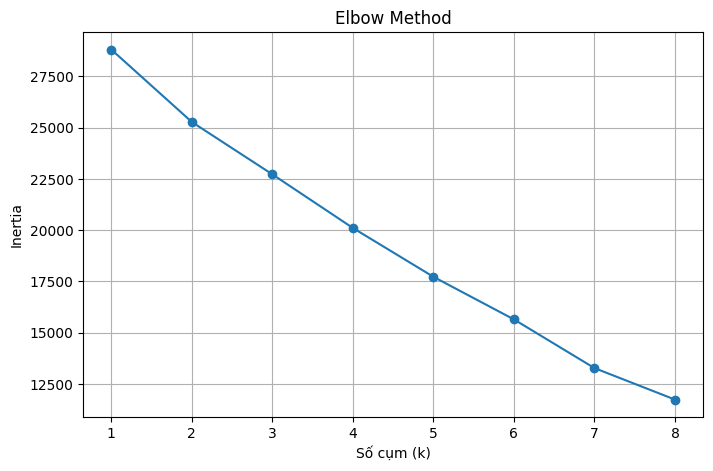

In [458]:
inertia_values = []
k_values = range(1, 9)

for k in k_values:
    model = KMeans(n_clusters=k, random_state=0, n_init=10)
    model.fit(df_scaled)
    inertia_values.append(model.inertia_)

inertia_table = pd.DataFrame({'k': list(k_values), 'inertia': inertia_values})
print(inertia_table)

plt.figure(figsize=(8, 5))
plt.plot(inertia_table['k'], inertia_table['inertia'], marker='o')
plt.xticks(list(k_values))
plt.xlabel('Số cụm (k)')
plt.ylabel('Inertia')
plt.title('Elbow Method')
plt.grid(True)
plt.show()

**Trả lời.**

7. Inertia nhỏ nhất trong bảng nằm ở k nào? Vì sao không chọn k đó làm số cụm?
8. Nhìn chỗ đường gãy, bạn chọn k nào cho phòng marketing? Có trùng k = 3 ở phần 4 không?
- Inertia nhỏ nhất ở k = 8, vì inertia luôn giảm hoặc giữ nguyên khi tăng số cụm. Không chọn k = 8 chỉ vì inertia thấp nhất: nhiều cụm làm mô hình phức tạp hơn, mục tiêu là cân bằng độ gọn và mức giảm inertia.
- Đường cong không có điểm gãy thật rõ; có thể chọn k = 3 như một lựa chọn gọn, dễ diễn giải cho bài toán marketing. Lựa chọn này trùng với k = 3 ở phần K-Means, nhưng nên xem đây là lựa chọn thực hành chứ không phải kết luận duy nhất từ biểu đồ.

## 6. KNN

KNN không gom cụm. KNN cần nhãn. Nhãn là Response. Bảng đặc trưng là bảng đã ghép ở phần 2, bản chưa chuẩn hóa.

Chia train/test, test_size=0.2, random_state=0, stratify theo Response.

Tạo một scaler mới, cùng loại với phần 3. Fit scaler chỉ trên tập train, rồi transform tập test. Không dùng lại scaler đã fit trên toàn bộ dữ liệu ở phần 3.

Thử n_neighbors trong 1, 3, 5, 7, 11, 21. Với mỗi k in accuracy và F1 của lớp 1. Chọn một k và in classification_report của k đó.


In [459]:
X = df2.copy()
y = df.loc[X.index, 'Response']

In [460]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=0,
    stratify=y
)

In [463]:
scaler_knn = StandardScaler()

X_train_scaled = scaler_knn.fit_transform(X_train)
X_test_scaled = scaler_knn.transform(X_test)

In [464]:
from sklearn.metrics import accuracy_score, f1_score

k_values = [1, 3, 5, 7, 11, 21]

results = []

for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k)

    knn.fit(X_train_scaled, y_train)

    y_pred = knn.predict(X_test_scaled)

    acc = accuracy_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred, pos_label=1, zero_division=0)

    results.append([k, acc, f1])

df_results = pd.DataFrame(
    results,
    columns=['k', 'Accuracy', 'F1 lớp 1']
)

print(df_results.round(3))

    k  Accuracy  F1 lớp 1
0   1     0.815     0.305
1   3     0.838     0.280
2   5     0.849     0.295
3   7     0.860     0.295
4  11     0.867     0.253
5  21     0.860     0.162


In [465]:
from sklearn.metrics import classification_report

best_k = int(df_results.loc[df_results['F1 lớp 1'].idxmax(), 'k'])

best_knn = KNeighborsClassifier(n_neighbors=best_k)

best_knn.fit(X_train_scaled, y_train)

y_pred_best = best_knn.predict(X_test_scaled)

print("Best k:", best_k)
print(classification_report(y_test, y_pred_best, zero_division=0))

Best k: 1
              precision    recall  f1-score   support

           0       0.88      0.91      0.89       377
           1       0.35      0.27      0.31        67

    accuracy                           0.82       444
   macro avg       0.61      0.59      0.60       444
weighted avg       0.80      0.82      0.80       444



**Trả lời.**

9. stratify theo Response giữ điều gì giữa train và test?
10. Fit scaler trên cả bảng rồi mới chia train/test thì sai ở đâu?
11. k bạn chọn là bao nhiêu? Accuracy cao hơn F1 lớp 1 thì đọc thêm chỉ số nào trước khi kết luận mô hình tốt?
- `stratify=y_knn` giữ tỷ lệ các lớp Response gần tương đương giữa tập train và test.
- Fit scaler trên toàn bộ dữ liệu làm thông tin phân phối của tập test lọt vào quá trình huấn luyện (data leakage). Chỉ fit trên train, sau đó dùng scaler đó transform test.
- Chọn k = 1 theo F1 lớp 1 cao nhất trong các giá trị đã thử (kết quả khoảng 0.305; accuracy khoảng 0.815). Cần xem precision, recall và F1 riêng của lớp 1, cùng confusion matrix; accuracy cao đơn lẻ có thể gây hiểu lầm khi Response bị mất cân bằng.